# **Loading The Files**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
BASE_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/datasets"

In [3]:
import pandas as pd

train = pd.read_parquet(f"{BASE_PATH}/v1_train.parquet")
val = pd.read_parquet(f"{BASE_PATH}/v1_val.parquet")
test = pd.read_parquet(f"{BASE_PATH}/v1_test.parquet")

# train_log = pd.read_parquet(f"{BASE_PATH}/v1_train_log.parquet")
# val_log = pd.read_parquet(f"{BASE_PATH}/v1_val_log.parquet")
# test_log = pd.read_parquet(f"{BASE_PATH}/v1_test_log.parquet")

# **Separating Predictors and Labels**

In [4]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train_log = train_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_trainA_log = train_log[target_cols[0]]
y_trainB_log = train_log[target_cols[1]]

X_val_log = val_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_valA_log = val_log[target_cols[0]]
y_valB_log = val_log[target_cols[1]]

del train_log
del val_log
gc.collect()

0

In [4]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train = train.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_trainA = train[target_cols[0]]
y_trainB = train[target_cols[1]]

X_val = val.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_valA = val[target_cols[0]]
y_valB = val[target_cols[1]]

del val
del train
gc.collect()

0

In [5]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

test_winner = test['playerA_wins']
X_test = test.drop(columns= target_cols + ['playerA_wins'], axis = 1)
y_testA = test[target_cols[0]]
y_testB = test[target_cols[1]]

# X_test_log = test_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)

del test
# del test_log
gc.collect()

0

# **Ablation Study**

## Preparation

### Datasets

In [7]:
from sklearn.preprocessing import StandardScaler
X_train_val = pd.concat([X_train, X_val], axis= 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis= 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis= 0)

scaler = StandardScaler()

X_train_val_log = pd.DataFrame(scaler.fit_transform(pd.concat([X_train_log, X_val_log], axis= 0)), 
                               columns= X_train_log.columns)
X_test_log = pd.DataFrame(scaler.transform(X_test_log), columns= X_test_log.columns)

In [8]:
ablation_A_predictions = pd.DataFrame()
ablation_B_predictions = pd.DataFrame()

PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_A.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_B.csv"

ablation_A_predictions.to_csv(PATH_A, index= False)
ablation_B_predictions.to_csv(PATH_B, index= False)

### Feature Groups

In [9]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_points_filled", "playerB_points_filled", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue":  ["playerA_matches_7d", "playerB_matches_7d", "playerA_matches_30d", "playerB_matches_30d", "playerA_wins_7d", 
                 "playerB_wins_7d", "playerA_wins_30d", "playerB_wins_30d", "playerA_winpct_7d", "playerB_winpct_7d", 
                 "playerA_winpct_30d", "playerB_winpct_30d", "playerA_minutes_tourney", "playerB_minutes_tourney", 
                 "playerA_avg_minutes_tourney", "playerB_avg_minutes_tourney", "playerA_losses_7d", "playerB_losses_7d", 
                 "playerA_losses_30d", "playerB_losses_30d"], 

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}


### Loading Models

In [10]:
!pip install catboost

In [11]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
RIDGE_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl"

ridge_A = joblib.load(RIDGE_PATH_A)
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
RIDGE_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl"

ridge_B = joblib.load(RIDGE_PATH_B)
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)


## Training Models & Making Predictions

### Without Removing Anything

In [13]:
anal_data = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/v1_results.parquet")

ablation_A_predictions = pd.DataFrame()
ablation_B_predictions = pd.DataFrame()

ablation_A_predictions["nothing"] = anal_data['p']
ablation_B_predictions['nothing'] = anal_data['q']

PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_A.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_B.csv"

ablation_A_predictions.to_csv(PATH_A, index= False)
ablation_B_predictions.to_csv(PATH_B, index= False)

### Removing Feature Groups

In [14]:
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import numpy as np


def ablation(feature_group):
    X_train_val_log_dropped = X_train_val_log.drop(columns= feature_groups[feature_group], errors='ignore')
    X_train_val_dropped = X_train_val.drop(columns= feature_groups[feature_group], errors='ignore')

    X_test_dropped = X_test.drop(columns= feature_groups[feature_group], errors='ignore')
    X_test_log_dropped = X_test_log.drop(columns= feature_groups[feature_group], errors='ignore')


    # Fetch parameters as dictionaries
    xgb_A_params = xgb_A.get_params()
    lgbm_A_params = lgbm_A.get_params()
    cat_A_params = cat_A.get_params()

    xgb_B_params = xgb_B.get_params()
    lgbm_B_params = lgbm_B.get_params()
    cat_B_params = cat_B.get_params()

    # Overwrite the GPU device settings to CPU
    xgb_A_params['device'] = 'cpu'
    xgb_B_params['device'] = 'cpu'

    for params in [lgbm_A_params, lgbm_B_params]:
        if 'device' in params: params['device'] = 'cpu'
        if 'device_type' in params: params['device_type'] = 'cpu'

    cat_A_params['task_type'] = 'CPU'
    cat_B_params['task_type'] = 'CPU'

    # Instantiate the new models safely
    ridge_A_dropped = Ridge(**ridge_A.get_params())
    xgb_A_dropped = XGBRegressor(**xgb_A_params)
    lgbm_A_dropped = LGBMRegressor(**lgbm_A_params)
    cat_A_dropped = CatBoostRegressor(**cat_A_params)

    ridge_B_dropped = Ridge(**ridge_B.get_params())
    xgb_B_dropped = XGBRegressor(**xgb_B_params)
    lgbm_B_dropped = LGBMRegressor(**lgbm_B_params)
    cat_B_dropped = CatBoostRegressor(**cat_B_params)
    
    

    ridge_A_dropped.fit(X_train_val_log_dropped, y_train_valA)
    xgb_A_dropped.fit(X_train_val_dropped, y_train_valA)
    lgbm_A_dropped.fit(X_train_val_dropped, y_train_valA)
    cat_A_dropped.fit(X_train_val_dropped, y_train_valA)

    ridge_B_dropped.fit(X_train_val_log_dropped, y_train_valB)
    xgb_B_dropped.fit(X_train_val_dropped, y_train_valB)
    lgbm_B_dropped.fit(X_train_val_dropped, y_train_valB)
    cat_B_dropped.fit(X_train_val_dropped, y_train_valB)


    ridgeA_preds = np.clip(ridge_A_dropped.predict(X_test_log_dropped), 0, 1)
    xgbA_preds = np.clip(xgb_A_dropped.predict(X_test_dropped), 0, 1)
    lgbmA_preds = np.clip(lgbm_A_dropped.predict(X_test_dropped), 0, 1)
    cat_A_preds = np.clip(cat_A_dropped.predict(X_test_dropped), 0, 1)

    ridgeB_preds = np.clip(ridge_B_dropped.predict(X_test_log_dropped), 0, 1)
    xgbB_preds = np.clip(xgb_B_dropped.predict(X_test_dropped), 0, 1)
    lgbmB_preds = np.clip(lgbm_B_dropped.predict(X_test_dropped), 0, 1)
    cat_B_preds = np.clip(cat_B_dropped.predict(X_test_dropped), 0, 1)

    ensembleA_preds = (ridgeA_preds + lgbmA_preds + xgbA_preds + cat_A_preds)/4
    ensembleB_preds = (ridgeB_preds + lgbmB_preds + xgbB_preds + cat_B_preds)/4

    return ensembleA_preds, ensembleB_preds


In [15]:
ablation_A_predictions = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_A.csv")
ablation_B_predictions = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_B.csv")

for i in feature_groups:
    ensembleA_preds, ensembleB_preds = ablation(i)

    ablation_A_predictions[f"{i}"] = ensembleA_preds
    ablation_B_predictions[f"{i}"] = ensembleB_preds
    print(f"{i} drop done.")


ablation_A_predictions.to_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_A.csv", index= False)
ablation_B_predictions.to_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_B.csv", index= False)    

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.887642 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 28933
[LightGBM] [Info] Number of data points in the train set: 207538, number of used features: 226
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing col-wise multi-threadin

## Computing MAE

In [16]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

pred_A = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_A.csv")
pred_B = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1/ablation_study_B.csv")

results = []

for col in pred_A.columns:

    mae_A = mean_absolute_error(y_testA, pred_A[col])
    mae_B = mean_absolute_error(y_testB, pred_B[col])

    results.append({
        "Feature Group Removed": col,
        "Player A MAE": mae_A,
        "Player B MAE": mae_B,
        "Average MAE": (mae_A + mae_B) / 2
    })

results = pd.DataFrame(results)

In [18]:
baseline = results.loc[
    results["Feature Group Removed"] == "nothing",
    "Average MAE"
].iloc[0]

results["Delta MAE"] = results["Average MAE"] - baseline

results = results.sort_values("Delta MAE", ascending=False)

In [19]:
results["% Increase"] = (
    results["Delta MAE"] / baseline
) * 100

results = results.sort_values("% Increase", ascending=False)

In [20]:
results.to_csv( "/content/drive/MyDrive/Projects/Tennis/v1/ablation_results.csv", index=False)

In [21]:
print(results)

     Feature Group Removed  Player A MAE  Player B MAE  Average MAE  \
2                      Elo      0.067747      0.068025     0.067886   
6                    Serve      0.067705      0.068063     0.067884   
7                   Return      0.067283      0.067586     0.067434   
5                  Fatigue      0.067144      0.067439     0.067291   
3                     Form      0.067120      0.067454     0.067287   
11              Experience      0.067025      0.067407     0.067216   
10  Surface Specialization      0.067017      0.067385     0.067201   
9                     Seed      0.067029      0.067351     0.067190   
8                 Physical      0.066971      0.067390     0.067180   
4                  Matchup      0.066999      0.067357     0.067178   
12      Tournament Context      0.066995      0.067348     0.067171   
0                  nothing      0.066997      0.067300     0.067148   
1                  Ranking      0.066937      0.067301     0.067119   

    D

## Plots

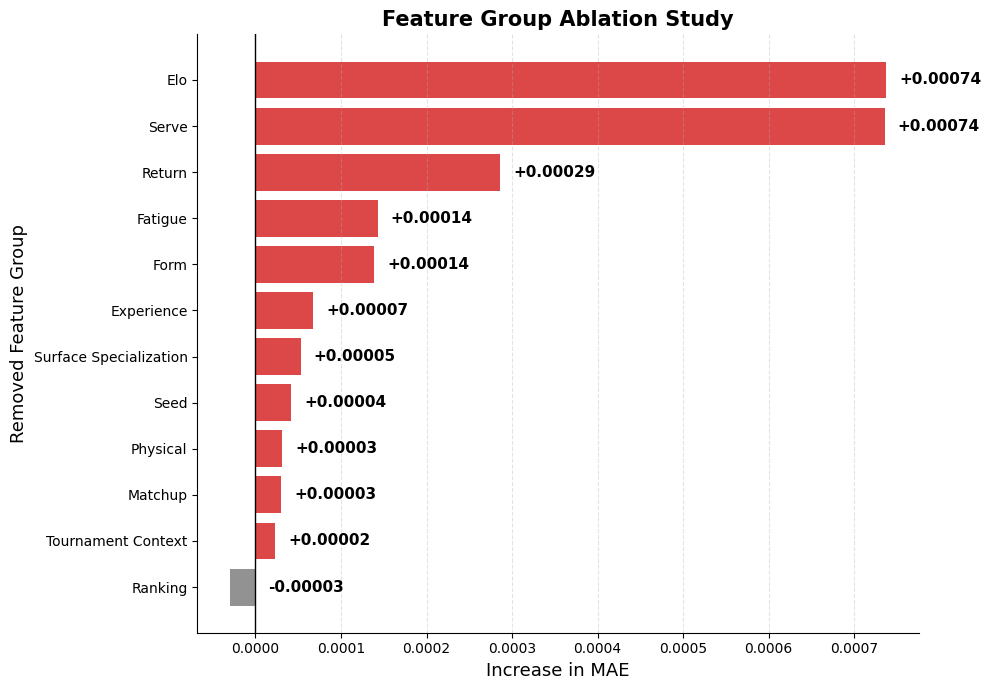

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = results[results["Feature Group Removed"] != "nothing"].copy()

# Sort by effect size (largest first)
plot_df = plot_df.sort_values("Delta MAE", ascending=False)

values = plot_df["Delta MAE"].values
labels = plot_df["Feature Group Removed"].values

# Colors
colors = ["tab:red" if x > 0 else "tab:gray" for x in values]

fig, ax = plt.subplots(figsize=(10,7))

bars = ax.barh(
    labels,
    values,
    color=colors,
    alpha=0.85
)

# Zero reference line
ax.axvline(0, color='black', linewidth=1)

# Light grid
ax.grid(axis='x', linestyle='--', alpha=0.35)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Largest at top
ax.invert_yaxis()

# Axis labels
ax.set_xlabel("Increase in MAE", fontsize=13)
ax.set_ylabel("Removed Feature Group", fontsize=13)
ax.set_title("Feature Group Ablation Study", fontsize=15, weight='bold')

# Dynamic annotation placement
x_range = max(values) - min(values)
offset = x_range * 0.02

for bar, value in zip(bars, values):

    y = bar.get_y() + bar.get_height()/2

    if value >= 0:
        # Positive bars
        ax.text(
            value + offset,
            y,
            f"+{value:.5f}",
            va='center',
            ha='left',
            fontsize=11,
            fontweight='bold'
        )

    else:
        # Always place negative labels just to the right of zero
        ax.text(
            offset,
            y,
            f"{value:.5f}",
            va='center',
            ha='left',
            fontsize=11,
            fontweight='bold'
        )

plt.tight_layout()

# Uncomment when making thesis figures
# plt.savefig("ablation_study.png", dpi=300, bbox_inches="tight")

plt.show()

# **Error Analysis**

## Preparing Data

In [11]:
import pandas as pd
import joblib
PATH = "/content/drive/MyDrive/Projects/Tennis/v1/v1_results.parquet"

predictions_df = joblib.load(PATH)
predictions_df.describe()

,p,q,best_of,playerA_wins,set_win_probA,match_win_probA
count,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000
mean,0.609784,0.609628,3.035656,0.495211,0.499838,0.499657
std,0.055408,0.055034,0.264654,0.499982,0.248845,0.309749
min,0.400652,0.381659,3.000000,0.000000,0.002792,0.000023
25%,0.575555,0.575814,3.000000,0.000000,0.309494,0.227379
50%,0.612797,0.612611,3.000000,0.000000,0.499698,0.499547
75%,0.647598,0.647618,3.000000,1.000000,0.689656,0.771781
max,0.795029,0.776756,5.000000,1.000000,0.999560,0.999999


In [12]:
#winner as predicted by model
predictions_df['playerA_wins_prediction'] = (predictions_df['match_win_probA'] >=0.5).astype('int')
predictions_df.describe()

,p,q,best_of,playerA_wins,set_win_probA,match_win_probA,playerA_wins_prediction
count,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000
mean,0.609784,0.609628,3.035656,0.495211,0.499838,0.499657,0.499586
std,0.055408,0.055034,0.264654,0.499982,0.248845,0.309749,0.500005
min,0.400652,0.381659,3.000000,0.000000,0.002792,0.000023,0.000000
25%,0.575555,0.575814,3.000000,0.000000,0.309494,0.227379,0.000000
50%,0.612797,0.612611,3.000000,0.000000,0.499698,0.499547,0.000000
75%,0.647598,0.647618,3.000000,1.000000,0.689656,0.771781,1.000000
max,0.795029,0.776756,5.000000,1.000000,0.999560,0.999999,1.000000


## Surface

### Preparation and Data Collection

In [11]:
import numpy as np
import pandas as pd

X_test_surface = X_test.copy()
surface_cols = ['surface_Carpet', 'surface_Clay', 'surface_Grass', 'surface_Hard']

X_test_surface['surface'] = X_test_surface[surface_cols].idxmax(axis= 1).str.replace("surface_", "", regex=False)

X_test_surface[["surface"]].sample(10)

,surface
26112,Clay
36534,Hard
23871,Hard
35987,Clay
48104,Hard
45524,Clay
27525,Clay
4513,Clay
18633,Clay
12456,Clay


In [8]:
import pandas as pd

X_train_val = pd.concat([X_train, X_val], axis= 0)
surface_cols = ['surface_Carpet', 'surface_Clay', 'surface_Grass', 'surface_Hard']

X_train_val['surface'] = X_train_val[surface_cols].idxmax(axis= 1).str.replace("surface_", "", regex=False)

print(X_train_val['surface'].value_counts(dropna= False))

surface
Hard      105096
Clay       82413
Grass      13293
Carpet      6736
Name: count, dtype: int64


### Evaluating Metrics

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

surface_results = list()

for surface in sorted(X_test_surface['surface'].unique()):
    idx = X_test_surface["surface"]==surface

    y_true = predictions_df['playerA_wins'][idx]
    y_pred = predictions_df['playerA_wins_prediction'][idx]
    y_prob = predictions_df['match_win_probA'][idx]

    surface_results.append({
        "Surface": surface, 
        "Matches": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred), 
        "Precision": precision_score(y_true, y_pred), 
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred), 
        "ROC-AUC": roc_auc_score(y_true, y_pred)
        })
    
surface_results = pd.DataFrame(surface_results)

surface_results = surface_results.sort_values("Accuracy", ascending= False)
surface_results

,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC
1,Clay,21575,0.698679,0.692903,0.703472,0.698147,0.698723
2,Grass,1147,0.694856,0.678261,0.702703,0.690265,0.695101
3,Hard,28954,0.694032,0.690398,0.692662,0.691528,0.694019
0,Carpet,209,0.650718,0.690265,0.672414,0.681223,0.648035


In [ ]:
#formatted table
surface_table = surface_results.copy()

surface_table["Accuracy"] *= 100
surface_table["Precision"] *= 100
surface_table["Recall"] *= 100
surface_table["F1"] *= 100
surface_table["ROC-AUC"] *= 100

surface_table = surface_table.round(2)

surface_table

,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC
1,Clay,21575,69.87,69.29,70.35,69.81,69.87
2,Grass,1147,69.49,67.83,70.27,69.03,69.51
3,Hard,28954,69.40,69.04,69.27,69.15,69.40
0,Carpet,209,65.07,69.03,67.24,68.12,64.80


In [17]:
# Error rate
surface_table["Error Rate (%)"] = (100 - surface_table["Accuracy"])

surface_table

,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC,Error Rate (%)
1,Clay,21575,69.87,69.29,70.35,69.81,69.87,30.13
2,Grass,1147,69.49,67.83,70.27,69.03,69.51,30.51
3,Hard,28954,69.40,69.04,69.27,69.15,69.40,30.60
0,Carpet,209,65.07,69.03,67.24,68.12,64.80,34.93


In [18]:
overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

surface_table["Difference in Accuracy"] = (surface_table["Accuracy"] - overall_accuracy).round(2)
surface_table

,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC,Error Rate (%),Difference in Accuracy
1,Clay,21575,69.87,69.29,70.35,69.81,69.87,30.13,0.29
2,Grass,1147,69.49,67.83,70.27,69.03,69.51,30.51,-0.09
3,Hard,28954,69.40,69.04,69.27,69.15,69.40,30.60,-0.18
0,Carpet,209,65.07,69.03,67.24,68.12,64.80,34.93,-4.51


### Plots

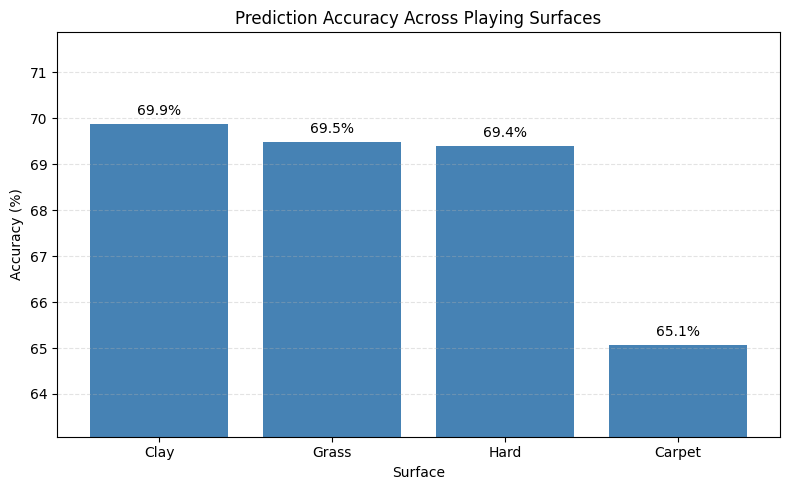

In [14]:
import matplotlib.pyplot as plt

plot_df = surface_table.sort_values("Accuracy", ascending=False)

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(plot_df["Surface"], plot_df["Accuracy"], color="steelblue")

ax.set_ylim(plot_df["Accuracy"].min()-2, plot_df["Accuracy"].max()+2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Surface")

ax.set_title("Prediction Accuracy Across Playing Surfaces")

ax.grid(axis="y", linestyle="--", alpha=0.35)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.2, f"{value:.1f}%", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

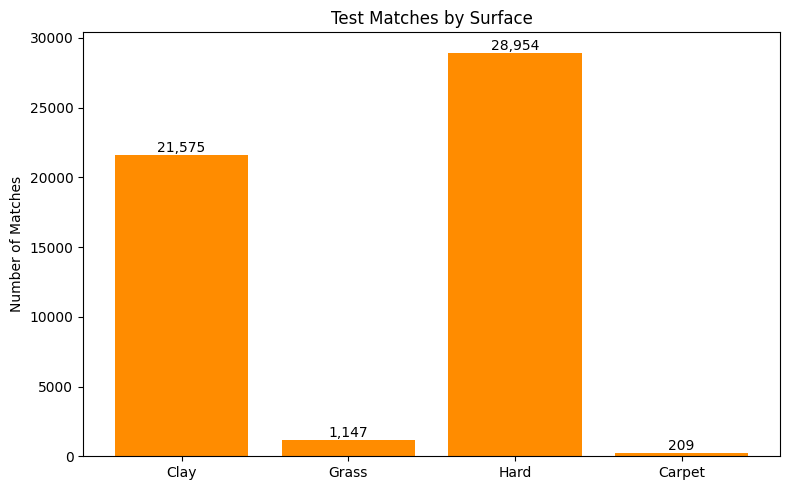

In [15]:
fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(surface_table["Surface"], surface_table["Matches"], color="darkorange")

ax.set_ylabel("Number of Matches")

ax.set_title("Test Matches by Surface")

for bar, value in zip(bars, surface_table["Matches"]):
    ax.text(bar.get_x()+bar.get_width()/2, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

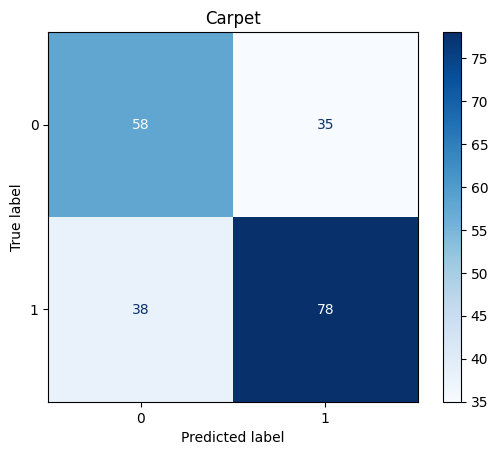

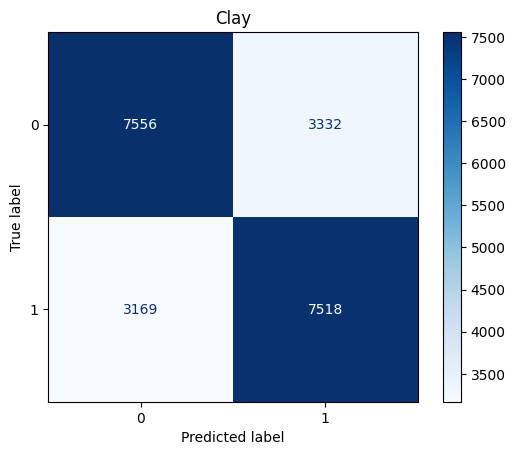

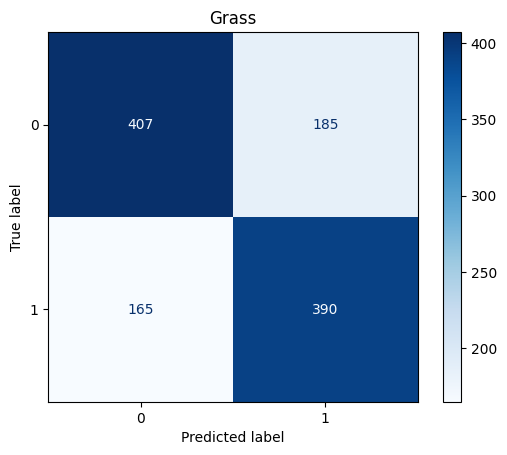

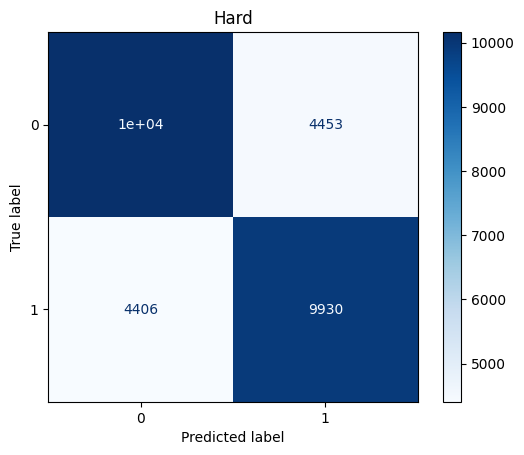

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

for surface in sorted(X_test_surface["surface"].unique()):
    idx = X_test_surface["surface"] == surface

    ConfusionMatrixDisplay.from_predictions(
        predictions_df['playerA_wins'][idx],
        predictions_df['playerA_wins_prediction'][idx],
        cmap="Blues"
    )

    plt.title(surface)
    plt.show()

## Elo 

### Preparation and Data Collection

In [8]:
X_test_elo = X_test.copy()

elo_features = ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio']

X_test_elo[elo_features].describe()

,playerA_elo,playerB_elo,elo_diff,playerA_surface_elo,playerB_surface_elo,surface_elo_diff,playerA_blended_elo,playerB_blended_elo,blended_elo_diff,elo_ratio,playerA_elo_momentum,playerB_elo_momentum,playerA_elo_volatility,playerB_elo_volatility,blended_elo_ratio,surface_elo_ratio
count,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000,51885.000000
mean,1664.987549,1665.320312,-0.332774,1575.088501,1575.635620,-0.547368,1602.058228,1602.541138,-0.482990,1.003877,1.664793,1.877671,12.314749,12.269973,1.002665,1.002469
std,181.395279,181.626221,145.434311,115.671791,115.588112,116.442871,131.987732,132.014496,120.562881,0.090757,29.181398,29.356424,10.903755,10.831764,0.077394,0.075438
min,1182.492065,1175.895874,-603.859314,1184.284546,1195.148926,-520.763977,1188.060181,1198.728516,-492.006989,0.688190,-237.912338,-262.072266,0.000000,0.000000,0.711294,0.713558
25%,1523.370972,1523.051514,-92.233444,1491.410278,1492.389771,-75.529373,1500.160522,1500.582397,-76.789841,0.946156,-10.396996,-10.088370,5.013768,5.033420,0.953577,0.953262
50%,1669.112793,1668.516602,-0.723298,1584.065308,1584.527344,-0.472990,1613.910645,1613.793701,-0.839374,0.999560,0.000000,0.194521,9.419351,9.395502,0.999475,0.999702
75%,1786.819824,1787.799438,90.878716,1657.558594,1658.228027,73.704376,1695.018921,1695.634277,75.376747,1.055967,13.893058,13.971811,16.675076,16.687685,1.047948,1.047869
max,2429.886230,2428.135010,670.203003,2095.191406,2093.016357,508.416351,2187.895020,2183.902344,541.915161,1.511531,217.801590,203.436737,94.069901,111.979897,1.414275,1.372499


In [10]:
import numpy as np
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['elo_diff'] = X_train_val['elo_diff'].abs()

elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']
X_train_val['elo_bin'] = pd.cut(X_train_val['elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

X_train_val['elo_bin'].value_counts()


,count
elo_bin,
100-200,57352
50-100,51671
>200,34091
0-25,33275
25-50,31149


In [13]:
elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']
X_train_val['surface_elo_diff'] = X_train_val['surface_elo_diff'].abs()
X_train_val['surface_elo_bin'] = pd.cut(X_train_val['surface_elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

X_train_val['surface_elo_bin'].value_counts()

,count
surface_elo_bin,
50-100,56870
100-200,54459
0-25,40189
25-50,37063
>200,18957


### Evaluating Metrics

In [12]:
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']

X_test_elo['elo_diff'] = X_test_elo['elo_diff'].abs()

X_test_elo['elo_bin'] = pd.cut(X_test_elo['elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

elo_results = list()

for group in elo_labels:
    idx = X_test_elo['elo_bin']==group

    if idx.sum==0:
        continue

    elo_results.append({
        "Elo Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx]),
        "ROC-AUC": roc_auc_score(predictions_df['playerA_wins'][idx], predictions_df['match_win_probA'][idx])

    })

elo_results = pd.DataFrame(elo_results)


overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100
elo_results["Difference in Accuracy"] = (elo_results["Accuracy"]*100 - overall_accuracy).round(2)

elo_results["Error Rate (%)"] = ((1 - elo_results["Accuracy"])*100).round(2)
elo_results["Accuracy"] = (elo_results['Accuracy']*100).round(2)
elo_results


,Elo Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-25,7788,58.37,0.620908,-11.21,41.63
1,25-50,7451,60.05,0.642156,-9.54,39.95
2,50-100,12607,64.88,0.692032,-4.70,35.12
3,100-200,15355,74.16,0.788916,4.58,25.84
4,>200,8684,86.54,0.902449,16.96,13.46


In [14]:
surface_elo_results = list()
X_test_elo['surface_elo_diff'] = X_test_elo['surface_elo_diff'].abs()

X_test_elo['elo_bin_surface'] = pd.cut(X_test_elo['surface_elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

for group in elo_labels:
    idx = X_test_elo['elo_bin_surface']==group

    if idx.sum==0:
        continue

    surface_elo_results.append({
        "Surface Elo Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx]),
        "ROC-AUC": roc_auc_score(predictions_df['playerA_wins'][idx], predictions_df['match_win_probA'][idx])

    })

surface_elo_results = pd.DataFrame(surface_elo_results)
overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100
surface_elo_results["Difference in Accuracy"] = (surface_elo_results["Accuracy"]*100 - overall_accuracy).round(2)

surface_elo_results["Error Rate (%)"] = ((1 - surface_elo_results["Accuracy"])*100).round(2)
surface_elo_results["Accuracy"] = (surface_elo_results['Accuracy']*100).round(2)
surface_elo_results

,Surface Elo Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-25,9575,62.13,0.672448,-7.45,37.87
1,25-50,8832,63.64,0.690672,-5.94,36.36
2,50-100,14087,66.47,0.718754,-3.12,33.53
3,100-200,14660,75.30,0.814113,5.72,24.70
4,>200,4731,87.30,0.914598,17.72,12.70


### Plots

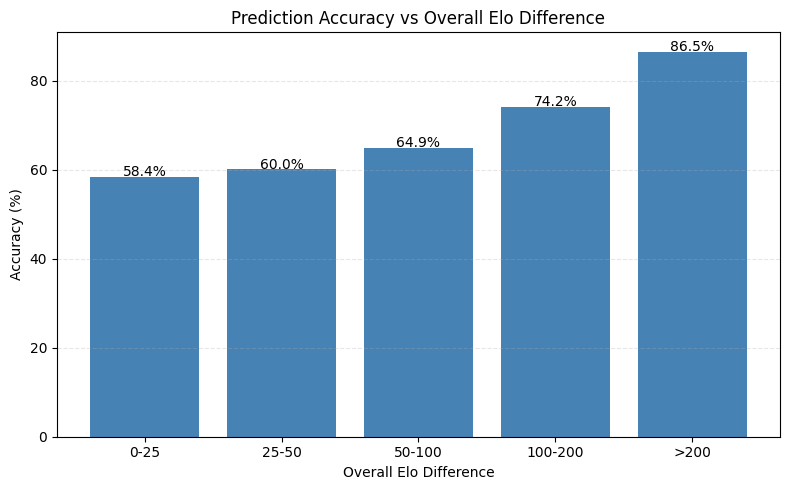

In [16]:
import matplotlib.pyplot as plt

plot_df = elo_results.copy()

# plot_df["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(plot_df["Elo Difference"], plot_df["Accuracy"], color="steelblue")

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Overall Elo Difference")
ax.set_title("Prediction Accuracy vs Overall Elo Difference")

ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.2, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

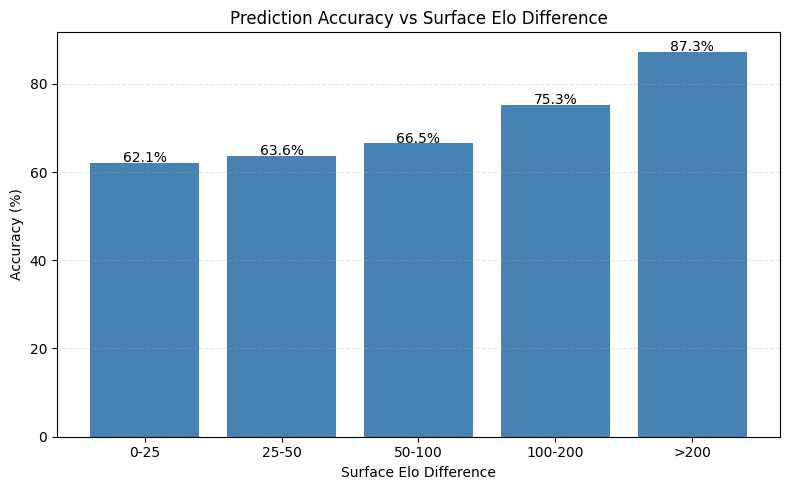

In [17]:
import matplotlib.pyplot as plt

plot_df = surface_elo_results.copy()

# plot_df["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Surface Elo Difference"],
    plot_df["Accuracy"],
    color="steelblue"
)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Surface Elo Difference")
ax.set_title("Prediction Accuracy vs Surface Elo Difference")

ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(
        bar.get_x()+bar.get_width()/2,
        value+0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Tournament Level

### Preparation and Data Collection

In [6]:
X_test_tourney = X_test.copy()

tourney_cols = ['tourney_level_A', 'tourney_level_C', 'tourney_level_D', 'tourney_level_F', 'tourney_level_G', 'tourney_level_M']

X_test_tourney['tourney_level'] = X_test_tourney[tourney_cols].idxmax(axis= 1).str.replace("tourney_level_", "", regex= False)

In [7]:
level_names = {
    "G": "Grand Slam",
    "M": "Masters 1000",
    "A": "ATP Tour",
    "F": "ATP Finals",
    "D": "Davis Cup",
    "C": "Challenger"
}

X_test_tourney['Tournament Level'] = X_test_tourney['tourney_level'].map(level_names)

In [9]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['tourney_level'] = X_train_val[tourney_cols].idxmax(axis= 1).str.replace("tourney_level_", "", regex= False)

X_train_val['Tournament Level'] = X_train_val['tourney_level'].map(level_names)
X_train_val['Tournament Level'].value_counts()

,count
Tournament Level,
Challenger,91989
ATP Tour,71543
Masters 1000,21192
Grand Slam,21047
Davis Cup,1240
ATP Finals,527


### Evaluating Metrics

In [15]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

level_results= list()
for level in X_test_tourney['Tournament Level'].unique():
    idx = X_test_tourney['Tournament Level']==level

    acc = accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx])*100

    level_results.append({
        "Tournament Level": level,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": roc_auc_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)": 100 - acc
    })

level_results = pd.DataFrame(level_results).sort_values("Accuracy", ascending=False)
level_results

,Tournament Level,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
2,ATP Tour,27965,71.593063,71.592970,2.012259,28.406937
0,Grand Slam,1645,71.003040,71.030410,1.422236,28.996960
1,Challenger,20117,67.256549,67.260826,-2.324255,32.743451
4,Davis Cup,104,65.384615,65.408805,-4.196188,34.615385
3,Masters 1000,1994,64.092277,64.104485,-5.488527,35.907723
5,ATP Finals,60,61.666667,62.556561,-7.914137,38.333333


### Plots

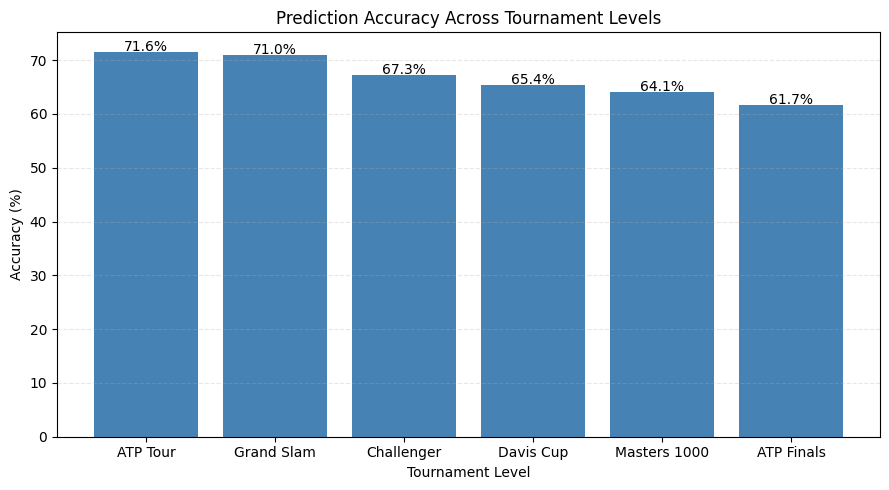

In [16]:
import matplotlib.pyplot as plt

plot_df = level_results.sort_values("Accuracy", ascending=False)

fig, ax = plt.subplots(figsize=(9,5))

bars = ax.bar(plot_df["Tournament Level"], plot_df["Accuracy"], color="steelblue")

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Tournament Level")
ax.set_title("Prediction Accuracy Across Tournament Levels")

ax.grid(axis="y", linestyle="--", alpha=0.3)

offset = 0.2

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+offset, f"{value:.1f}%", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

## Round

### Preparation and Data Collection

In [18]:
X_test_round = X_test.copy()

round_cols= ['round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
            'round_R32', 'round_R64', 'round_RR']

X_test_round['Round'] = X_test_round[round_cols].idxmax(axis= 1).str.replace("round_", "", regex= False)

In [19]:
round_names = {
    "BR": "Bronze Match",
    "ER": "Early Round",
    "F": "Final",
    "Q1": "Qualifying R1",
    "Q2": "Qualifying R2",
    "Q3": "Qualifying R3",
    "QF": "Quarterfinal",
    "R128": "Round of 128",
    "R64": "Round of 64",
    "R32": "Round of 32",
    "R16": "Round of 16",
    "RR": "Round Robin"
}

X_test_round["Round"] = X_test_round['Round'].map(round_names)

In [21]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['Round'] = X_train_val[round_cols].idxmax(axis= 1).str.replace("round_", "", regex= False)

X_train_val["Round"] = X_train_val['Round'].map(round_names)
X_train_val['Round'].value_counts()

,count
Round,
Round of 32,69826
Round of 16,35667
Qualifying R1,23023
Round of 64,18835
Quarterfinal,17840
Qualifying R2,12962
Round of 128,10213
Bronze Match,9018
Final,4537


### Evaluating Metrics

In [22]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

round_results = list()

for rnd in X_test_round["Round"].unique():
    idx = X_test_round["Round"]==rnd

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100

    round_results.append({
        "Round": rnd,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": roc_auc_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)": 100 - acc
    })

round_results = pd.DataFrame(round_results).sort_values("Accuracy", ascending=False)

round_results


,Round,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,Qualifying R1,6113,72.174055,72.164296,2.593252,27.825945
5,Round of 32,20945,71.110050,71.111369,1.529246,28.889950
6,Round of 16,10473,70.543302,70.543170,0.962498,29.456698
4,Round of 64,840,67.142857,67.148232,-2.437947,32.857143
7,Quarterfinal,5193,66.589640,66.592110,-2.991164,33.410360
3,Round of 128,832,66.346154,66.349273,-3.234650,33.653846
1,Qualifying R2,3223,65.218740,65.225246,-4.362063,34.781260
8,Bronze Match,2606,64.888718,64.879182,-4.692085,35.111282
9,Final,1342,63.263785,63.218433,-6.317018,36.736215
10,Round Robin,206,61.165049,61.188119,-8.415755,38.834951


### Plots

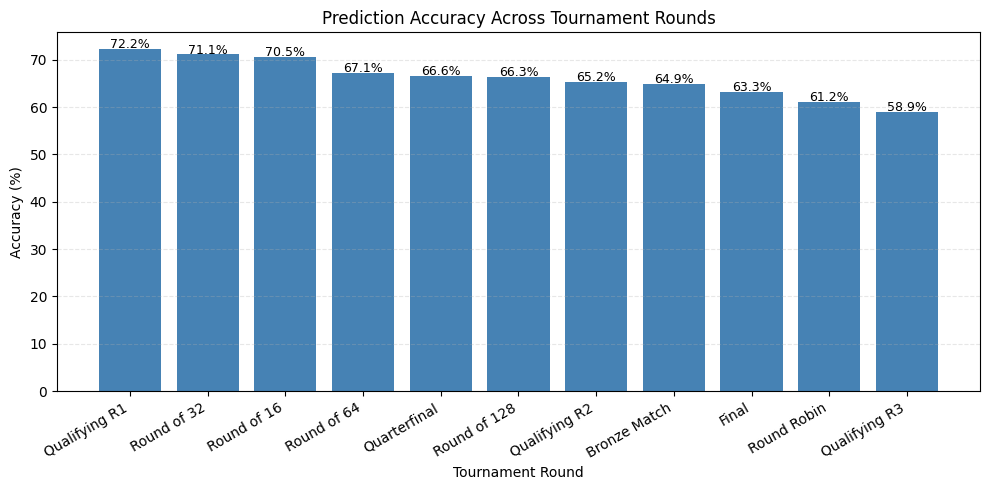

In [23]:
import matplotlib.pyplot as plt

plot_df = round_results.sort_values(
    "Accuracy",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10,5))

bars = ax.bar(
    plot_df["Round"],
    plot_df["Accuracy"],
    color="steelblue"
)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Tournament Round")
ax.set_title("Prediction Accuracy Across Tournament Rounds")

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=30, ha="right")

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x()+bar.get_width()/2,
        value+0.2,
        f"{value:.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

## Rank Difference

### Preparation and Data Analysis

In [6]:
X_test_rank = X_test.copy()

X_test_rank['rank_diff'] = X_test_rank['rank_diff'].abs()

In [8]:
import numpy as np
import pandas as pd

rank_bins = [0, 10, 25, 50, 100, np.inf]
rank_labels = ['0-10', '10-25', '25-50', '50-100', '100+']

X_test_rank['Rank Difference'] = pd.cut(X_test_rank['rank_diff'], bins= rank_bins, labels= rank_labels, include_lowest= True)
X_test_rank['Rank Difference'].value_counts()

,count
Rank Difference,
100+,36192
50-100,6527
25-50,4171
10-25,2707
0-10,2288


In [9]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['rank_diff'] = X_train_val['rank_diff'].abs()

X_train_val['Rank Difference'] = pd.cut(X_train_val['rank_diff'], bins= rank_bins, labels= rank_labels, include_lowest= True)
X_train_val['Rank Difference'].value_counts()

,count
Rank Difference,
100+,81676
50-100,45304
25-50,36598
10-25,25726
0-10,18234


### Evaluating Metrics

In [ ]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

rank_difference_results = list()

for group in rank_labels:
    idx = X_test_rank['Rank Difference']==group

    if idx.sum()==0:
        continue
    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100
    

    rank_difference_results.append({
        "Rank Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": acc, 
        "ROC-AUC": roc_auc_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy, 
        "Error Rate (%)": 100- acc
    })

rank_difference_results = pd.DataFrame(rank_difference_results)
rank_difference_results

,Rank Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-10,2288,61.319930,61.322493,-8.260874,38.680070
1,10-25,2707,61.654969,61.672919,-7.925835,38.345031
2,25-50,4171,62.886598,62.840143,-6.694206,37.113402
3,50-100,6527,63.704612,63.712803,-5.876192,36.295388
4,100+,36192,72.527078,72.527571,2.946274,27.472922


### Plots

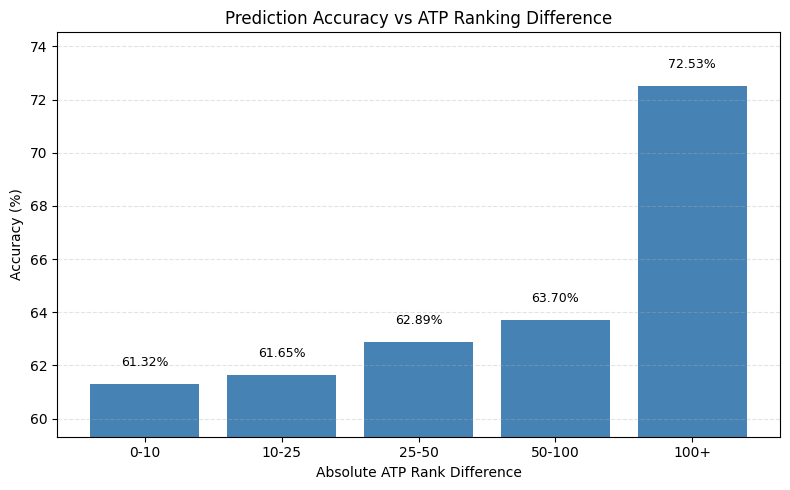

In [27]:
import matplotlib.pyplot as plt

plot_df = rank_difference_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Rank Difference"],
    plot_df["Accuracy"],
    color="steelblue"
)

# Dynamic y-axis
ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Absolute ATP Rank Difference")
ax.set_title("Prediction Accuracy vs ATP Ranking Difference")

ax.grid(axis="y", linestyle="--", alpha=0.35)

# Labels
offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.show()

## Highest Ranked Player

### Preparation and Data Analysis

In [21]:
X_test_rank['Best Rank'] = np.minimum(X_test_rank['playerA_rank_filled'], X_test_rank['playerB_rank_filled'])

best_rank_bins = [0, 10, 20, 50, 100, np.inf]
best_rank_labels = ["Top 10", "11-20", "21-50", "51-100", ">100"]

X_test_rank["Highest Rank Analysis"] = pd.cut(X_test_rank["Best Rank"], bins= best_rank_bins, labels= best_rank_labels, 
                                                include_lowest= True)

X_test_rank["Highest Rank Analysis"].value_counts()

,count
Highest Rank Analysis,
>100,45190
51-100,2938
21-50,1802
Top 10,1086
11-20,869


In [22]:
X_train_val['Best Rank'] = np.minimum(X_train_val['playerA_rank_filled'], X_train_val['playerB_rank_filled'])

best_rank_bins = [0, 10, 20, 50, 100, np.inf]
best_rank_labels = ["Top 10", "11-20", "21-50", "51-100", ">100"]

X_train_val['Highest Rank Analysis'] = pd.cut(X_train_val['Best Rank'], bins= best_rank_bins, labels= best_rank_labels, 
                                                include_lowest= True)
X_train_val['Highest Rank Analysis'].value_counts()

,count
Highest Rank Analysis,
>100,104099
51-100,36784
21-50,31870
Top 10,19645
11-20,15140


### Evaluation Metrics

In [25]:
best_rank_results = []

for group in best_rank_labels:
    idx = X_test_rank["Highest Rank Analysis"] == group

    if idx.sum() == 0:
        continue

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100


    best_rank_results.append({
        "Highest Ranked Player": group,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": roc_auc_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)":
            100 - acc
    })

best_rank_results = pd.DataFrame(best_rank_results)
best_rank_results

,Highest Ranked Player,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,Top 10,1086,75.690608,75.725524,6.109804,24.309392
1,11-20,869,68.239356,68.221942,-1.341448,31.760644
2,21-50,1802,65.094340,65.073993,-4.486464,34.905660
3,51-100,2938,65.724983,65.737803,-3.855821,34.275017
4,>100,45190,69.889356,69.891062,0.308552,30.110644


### Plots

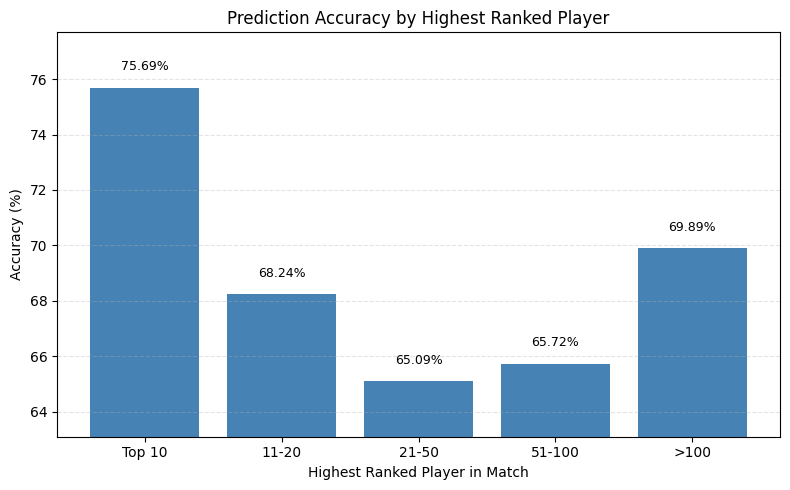

In [28]:
import matplotlib.pyplot as plt

plot_df = best_rank_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Highest Ranked Player"],
    plot_df["Accuracy"],
    color="steelblue"
)

ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Highest Ranked Player in Match")
ax.set_title("Prediction Accuracy by Highest Ranked Player")

ax.grid(axis="y", linestyle="--", alpha=0.35)

offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.show()

## Experience

### Preparation and Data Analysis

In [34]:
X_test_experience = X_test.copy()

X_test_experience['Average Experience'] = (X_test_experience['playerA_career_matches'] + 
                                                    X_test_experience['playerB_career_matches'])/2


In [35]:
experience_bins = [0,100,250,500,1000,np.inf]
experience_labels = ["0-100", "100-250", "250-500", "500-1000", ">1000"]

X_test_experience['Experience'] = pd.cut(X_test_experience['Average Experience'], bins= experience_bins, labels= experience_labels,
                                            include_lowest= True)
X_test_experience['Experience'].value_counts()

,count
Experience,
250-500,15984
100-250,15816
0-100,11681
500-1000,8305
>1000,99


In [37]:
X_train_val['Average Experience'] = (X_train_val['playerA_career_matches'] + X_train_val['playerB_career_matches'])/2

X_train_val['Experience'] = pd.cut(X_train_val['Average Experience'], bins= experience_bins, labels= experience_labels, 
                                    include_lowest= True)
X_train_val['Experience'].value_counts()

,count
Experience,
250-500,97599
500-1000,58122
100-250,39594
0-100,11558
>1000,665


### Evaluation Metrics

In [38]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

experience_results= list()

for group in experience_labels:
    idx= X_test_experience["Experience"]==group

    if idx.sum==0:
        continue

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx])*100

    experience_results.append({
        "Experience": group, 
        "Matches": idx.sum(), 
        "Accuracy": acc, 
        "ROC-AUC": roc_auc_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100,
        "Difference in Accuracy": acc-overall_accuracy, 
        "Error Rate (%)": 100-acc
    })

experience_results = pd.DataFrame(experience_results)
experience_results

,Experience,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-100,11681,72.082870,72.080972,2.502066,27.917130
1,100-250,15816,71.750126,71.750046,2.169323,28.249874
2,250-500,15984,67.429930,67.442995,-2.150874,32.570070
3,500-1000,8305,65.972306,65.973005,-3.608498,34.027694
4,>1000,99,77.777778,77.795918,8.196974,22.222222


### Plots

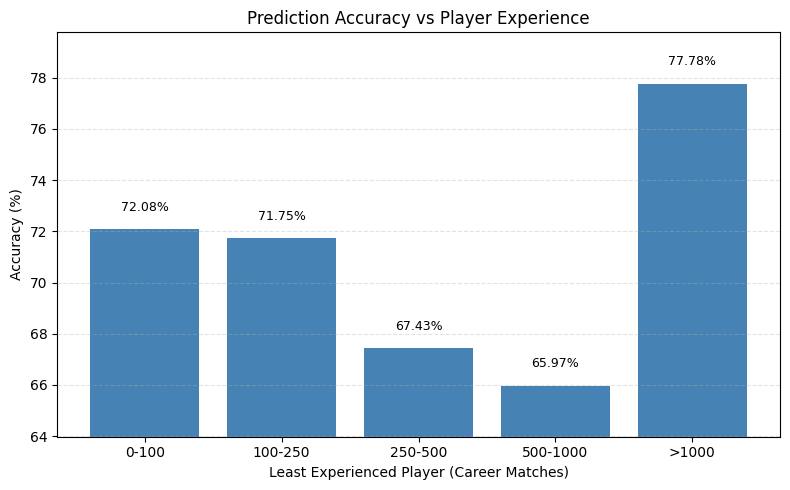

In [39]:
import matplotlib.pyplot as plt

plot_df = experience_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Experience"],
    plot_df["Accuracy"],
    color="steelblue"
)

# Dynamic y-axis
ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_xlabel("Least Experienced Player (Career Matches)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Prediction Accuracy vs Player Experience")

ax.grid(axis="y", linestyle="--", alpha=0.35)

# Label spacing
offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()